# Extended Data Fig. 2: adaptive tiling and batch packing

Adaptive tiling and bin-packed batching keep IST graphs within a fixed memory budget.
Panel a is compiled from published dataset summaries; panels b–e use transcript coordinates only.

| | |
|---|---|
| Data | Transcripts of six sections on three platforms; public Xenium dataset summaries |
| Compute | CUDA GPU. Tile occupancies and batch efficiencies are cached in `results/ed_figure_2`. |
| Output | `results/ed_figure_2/panel_{a,bc,d,e}.{pdf,png}` |

Datasets not in `sg_utils.datasets` are expected under `DATA_DIR`: `xenium_mouse_liver/xenium` (Xenium v1 mouse liver), `cosmx_pancreas/cosmx` ([CosMx human pancreas flat files](https://brukerspatialbiology.com/products/cosmx-spatial-molecular-imager/ffpe-dataset/cosmx-smi-human-pancreas-ffpe-dataset/)) and `xenium_healthy_colon_base/xenium` ([Xenium human colon, non-diseased, base panel](https://www.10xgenomics.com/datasets/human-colon-preview-data-xenium-human-colon-gene-expression-panel-1-standard)).

In [1]:
import json
import logging
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", category=FutureWarning)  # deprecation notices raised on import

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import scanpy as sc
import seaborn as sns
import torch
from matplotlib import cm
from matplotlib import colors as mcolors
from segger.data.tiling import QuadTreeTiling, SquareTiling
from tqdm.auto import tqdm

import sg_utils as sg
from sg_utils.pl.tiling import plot_tiling
from sg_utils.tl.scaling import (
    load_transcript_positions,
    matched_quadtree_capacity,
    matched_square_side_length,
    packing_efficiencies,
    tile_counts,
)

logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
ASSETS = Path(sg.pl.__file__).parent / "assets"
plt.style.use(ASSETS / "default.mplstyle")
plt.rcParams["savefig.bbox"] = "tight"
tiling_palette = {"fixed": "#E81F64", "adaptive": "#FFC10E"}
packing_palette = {"fixed": "#E81F64", "sequential": "#E81F64", "ffd": "#FFC10E", "bfd": "#FFC10E"}

In [2]:
DATA_DIR = Path("../data")
OUT_DIR = Path("../results/ed_figure_2")
NODES_PER_TILE = 50_000  # adaptive tiling capacity
BATCH_CAPACITY = 150_000  # transcripts per batch

## Download the data

In [3]:
xenium_datasets = sg.datasets.fetch("xenium_healthy_colon", DATA_DIR, files=["xenium_datasets"])["xenium_datasets"]
raw_dirs = {
    name: sg.datasets.fetch(name, DATA_DIR, files=["xenium"])["xenium"]
    for name in ["xenium_breast", "xenium_healthy_colon", "xenium_crc", "xenium_nsclc"]
}
raw_dirs |= {
    "xenium_mouse_liver": DATA_DIR / "xenium_mouse_liver" / "xenium",
    "cosmx_pancreas": DATA_DIR / "cosmx_pancreas" / "cosmx",
    "xenium_healthy_colon_base": DATA_DIR / "xenium_healthy_colon_base" / "xenium",
}
SAMPLES = {
    "xenium_breast": "Xenium Prime\nHuman Breast Cancer",
    "xenium_healthy_colon": "Xenium v1.0\nHuman Colon",
    "xenium_crc": "Xenium v1.0\nHuman Colorectal Cancer",
    "xenium_nsclc": "Xenium v1.0\nHuman Lung Cancer",
    "xenium_mouse_liver": "Xenium v1.0\nMouse Liver",
    "cosmx_pancreas": "CosMX\nHuman Pancreas",
}
PLATFORMS = {name: "cosmx" if name.startswith("cosmx") else None for name in SAMPLES}
OUT_DIR.mkdir(parents=True, exist_ok=True)

## Panel a: dataset sizes

Graph nodes (transcripts plus cells reported by each vendor's onboard analysis) of the public preview datasets per platform; dashed lines, the three largest OGB Large-Scale Challenge graphs.
The table is written to `OUT_DIR/ist_dataset_sizes.csv`.

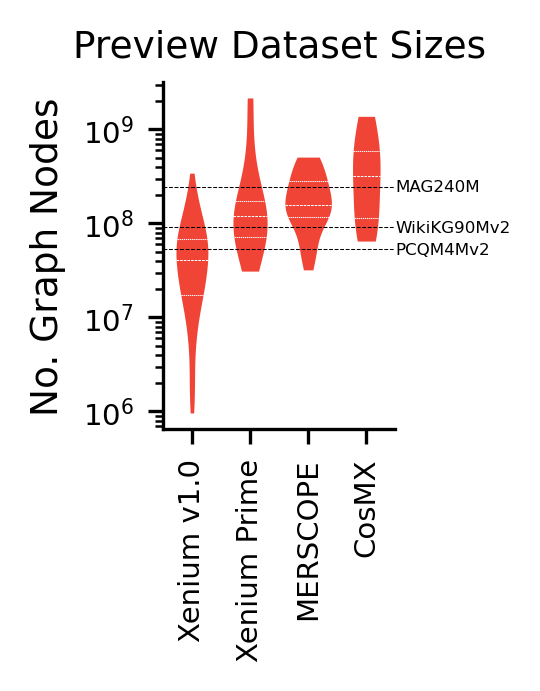

In [4]:
OGB_LSC_NODES = {"MAG240M": 244_160_499, "WikiKG90Mv2": 91_230_610, "PCQM4Mv2": 52_970_652}

cosmx = pl.DataFrame(
    [
        ("human_colon", 493_834, 829_810_448),
        ("human_breast", 147_846, 303_379_992),
        ("human_lymph", 1_852_946, 1_378_108_235),
        ("human_liver", 464_126, 533_910_466),
        ("mouse_brain_hippocampus", 38_987, 109_600_000),
        ("mouse_brain_coronal_hemisphere", 48_011, 116_100_000),
        ("human_pancreas", 48_951, 64_960_677),
        ("human_frontal_cortex", 194_065, 331_132_591),
    ],
    schema=["dataset", "cells", "transcripts"],
    orient="row",
).with_columns(pl.lit("CosMX").alias("platform"))
merscope = pl.DataFrame(
    [
        ("mouse_embryo_e10", 143_307, 60_016_436),
        ("mouse_embryo_e12", 131_035, 55_676_335),
        ("mouse_embryo_e14", 330_923, 139_780_442),
        ("human_cortex_normal", 68_778, 43_169_680),
        ("human_cortex_ad", 184_454, 125_495_863),
        ("human_breast_cancer_tma", 329_895, 117_568_432),
        ("human_colon_cancer", 703_879, 150_234_785),
        ("human_brain_ff", 147_402, 217_427_270),
        ("mouse_brain_ff", 112_158, 214_805_552),
        ("human_brain_ad_ff", 137_627, 117_109_445),
        ("human_breast_cancer", 713_121, 490_398_542),
        ("human_colon_cancer_1", 677_451, 411_716_053),
        ("human_colon_cancer_2", 817_588, 507_576_479),
        ("human_liver_cancer_1", 568_355, 272_021_991),
        ("human_liver_cancer_2", 598_141, 283_068_068),
        ("human_lung_cancer_1", 353_762, 144_388_044),
        ("human_lung_cancer_2", 836_739, 425_594_806),
        ("human_melanoma_1", 468_138, 160_181_929),
        ("human_melanoma_2", 207_869, 75_617_432),
        ("human_ovarian_cancer_1", 358_485, 197_365_319),
        ("human_ovarian_cancer_2", 254_347, 121_798_559),
        ("human_ovarian_cancer_3", 71_381, 32_054_444),
        ("human_ovarian_cancer_4", 212_425, 119_742_527),
        ("human_prostate_cancer_1", 721_668, 291_996_280),
        ("human_prostate_cancer_2", 993_825, 221_331_615),
        ("human_uterine_cancer", 843_285, 374_580_211),
    ],
    schema=["dataset", "cells", "transcripts"],
    orient="row",
).with_columns(pl.lit("MERSCOPE").alias("platform"))
xenium = pl.read_csv(xenium_datasets).select(
    pl.concat_str(["Dataset", "Section"], separator=" | ").alias("dataset"),
    pl.col("Cells detected").cast(pl.Int64).alias("cells"),
    pl.col("High quality decoded transcripts detected").cast(pl.Int64).alias("transcripts"),
    pl.col("Product").replace({
        "In Situ Gene Expression v1.0": "Xenium v1.0",
        "In Situ Gene Expression Xenium Prime": "Xenium Prime",
    }).alias("platform"),
)
inventory = pl.concat([xenium, merscope, cosmx]).with_columns((pl.col("cells") + pl.col("transcripts")).alias("nodes"))
inventory.write_csv(OUT_DIR / "ist_dataset_sizes.csv")
platform_order = ["Xenium v1.0", "Xenium Prime", "MERSCOPE", "CosMX"]

fig, ax = plt.subplots(1, 1, figsize=(1, 1.5))
sns.violinplot(
    inventory, x="platform", y="nodes", order=platform_order, log_scale=(False, True), cut=0, linewidth=0,
    saturation=1, inner="quart", inner_kws=dict(linewidth=0.25, color="w"), ax=ax,
)
xmax = ax.get_xlim()[1]
for dataset, nodes in OGB_LSC_NODES.items():
    ax.axhline(nodes, lw=0.25, c="k", ls="--")
    ax.text(xmax, nodes, dataset, fontsize=4, va="center")
ax.tick_params(axis="x", rotation=90)
ax.set_xlabel("")
ax.set_ylabel("No. Graph Nodes")
ax.set_title("Preview Dataset Sizes")
sg.pl.save_panel(fig, OUT_DIR / "panel_a")

## Panels b and c: fixed and adaptive tilings

Healthy colon (base panel) tiled with 200 µm squares (b) and with a quadtree whose capacity gives the same mean tile width (c), coloured by transcripts per tile.

Invalid quadtree generated with max_size=36000.0. Retry with max_size=46000.0.


Invalid quadtree generated with max_size=32000.0. Retry with max_size=42000.0.


Invalid quadtree generated with max_size=42000.0. Retry with max_size=52000.0.


Invalid quadtree generated with max_size=30000.0. Retry with max_size=40000.0.


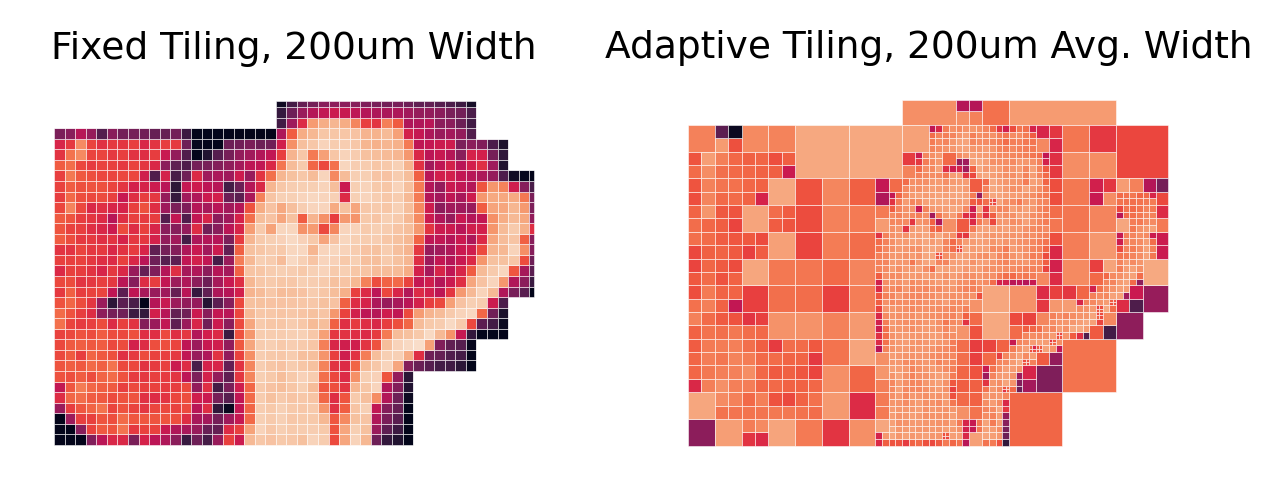

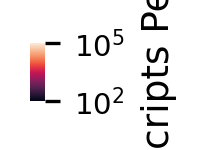

In [5]:
MAP_WIDTH = 200.0
positions = load_transcript_positions(raw_dirs["xenium_healthy_colon_base"], device="cuda")
tiling_fixed = SquareTiling(positions, MAP_WIDTH)
tiling_adaptive = QuadTreeTiling(positions, matched_quadtree_capacity(positions, MAP_WIDTH))

fig, axes = plt.subplots(1, 2, figsize=(5, 2.5))
titles = ["Fixed Tiling, 200um Width", "Adaptive Tiling, 200um Avg. Width"]
for ax, tiling, title in zip(axes, [tiling_fixed, tiling_adaptive], titles):
    plot_tiling(tiling, tile_counts(positions, tiling, include_empty=True), ax=ax, vmin=1e2, vmax=1e5)
    ax.set_title(title)
sg.pl.save_panel(fig, OUT_DIR / "panel_bc")

fig, ax = plt.subplots(1, 1, figsize=(0.0625, 0.25))
colorbar = fig.colorbar(
    cm.ScalarMappable(norm=mcolors.LogNorm(vmin=1e2, vmax=1e5), cmap="rocket"),
    cax=ax, orientation="vertical", ticks=[1e2, 1e5], drawedges=False,
)
colorbar.outline.set_visible(False)
colorbar.set_label("Transcripts Per Tile")
sg.pl.save_panel(fig, OUT_DIR / "panel_bc_colorbar")
del positions
torch.cuda.empty_cache()

## Panel d: tile occupancy

Transcripts per occupied tile, adaptive (capacity 50,000) against fixed squares sized so that the average tissue-covered tile holds 50,000 transcripts (density over occupied 50 µm tiles).
Percentages, occupied tiles above the budget (top, fixed; bottom, adaptive).

In [6]:
path_occupancy = OUT_DIR / "tile_occupancy.parquet"
if path_occupancy.exists():
    occupancy = pl.read_parquet(path_occupancy)
else:
    frames = []
    for sample in tqdm(SAMPLES):
        positions = load_transcript_positions(raw_dirs[sample], platform=PLATFORMS[sample], device="cuda")
        tilings = {
            "adaptive": QuadTreeTiling(positions, NODES_PER_TILE),
            "fixed": SquareTiling(positions, matched_square_side_length(positions, NODES_PER_TILE)),
        }
        for name, tiling in tilings.items():
            counts = tile_counts(positions, tiling)
            frames.append(pl.DataFrame({
                "transcripts": counts.numpy(),
                "sample": np.full(len(counts), sample),
                "tiling": np.full(len(counts), name),
            }))
        del positions
        torch.cuda.empty_cache()
    occupancy = pl.concat(frames)
    occupancy.write_parquet(path_occupancy)

over_budget = (
    occupancy
    .with_columns(pl.col("transcripts").gt(NODES_PER_TILE).alias("over"))
    .group_by(["sample", "tiling"])
    .agg(pl.col("over").mean())
)

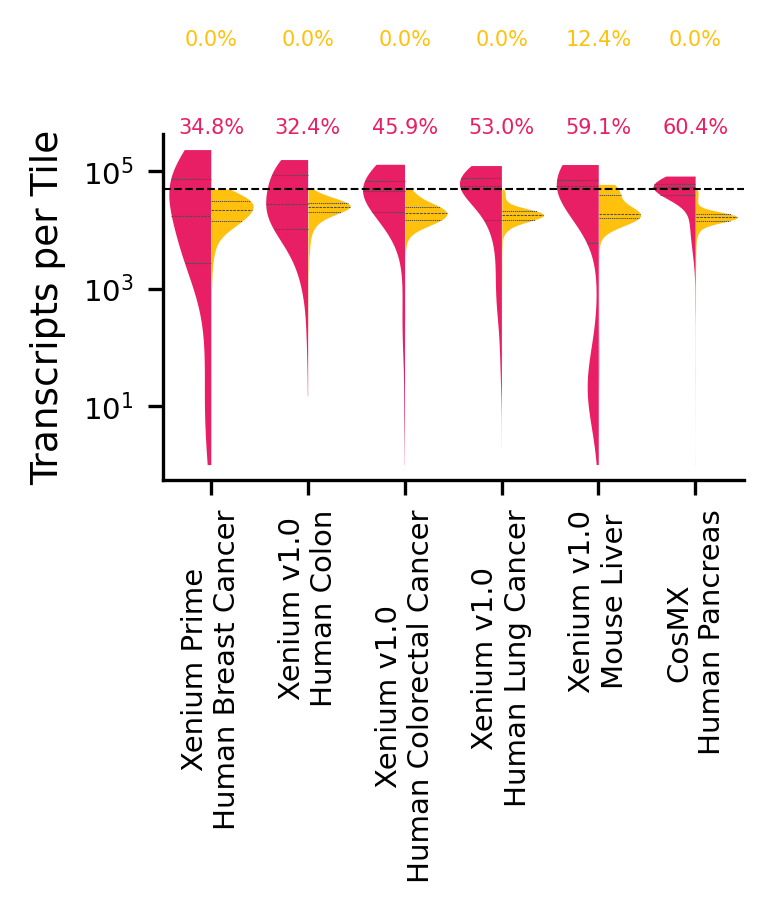

In [7]:
fig, ax = plt.subplots(1, 1, figsize=(2.5, 1.5))
sns.violinplot(
    occupancy, x="sample", y="transcripts", hue="tiling", order=list(SAMPLES), hue_order=["fixed", "adaptive"],
    palette=tiling_palette, log_scale=(False, True), split=True, cut=0, gap=0.01, width=0.875, linewidth=0,
    bw_adjust=2, saturation=1, inner="quart", inner_kws=dict(linewidth=0.25), common_norm=False,
    density_norm="width", legend=False, ax=ax,
)
ax.axhline(NODES_PER_TILE, lw=0.5, ls="--", c="k")
ymax = ax.get_ylim()[1]
for x, sample in enumerate(SAMPLES):
    for i, tiling in enumerate(["fixed", "adaptive"]):
        fraction = over_budget.filter(pl.col("sample").eq(sample) & pl.col("tiling").eq(tiling))["over"][0]
        ax.text(x, ymax * (10 ** (1.5 * i)), f"{fraction:.1%}", fontsize=5, ha="center", color=tiling_palette[tiling])
ax.set_xticks(range(len(SAMPLES)), list(SAMPLES.values()), rotation=90)
ax.set_xlabel("")
ax.set_ylabel("Transcripts per Tile")
sg.pl.save_panel(fig, OUT_DIR / "panel_d")

## Panel e: batch packing efficiency

Transcripts per batch over the 150,000-transcript capacity, packing the same adaptive tiles of all datasets: a fixed number of tiles per batch, the greedy PyTorch Geometric `DynamicBatchSampler` (`sequential`), and first- and best-fit decreasing bin packing (`ffd`, `bfd`, used by Segger).

In [8]:
path_packing = OUT_DIR / "batch_packing.parquet"
if path_packing.exists():
    packing = pl.read_parquet(path_packing)
else:
    frames = []
    for sample in tqdm(SAMPLES):
        counts = occupancy.filter(pl.col("sample").eq(sample) & pl.col("tiling").eq("adaptive"))["transcripts"].to_list()
        frames.append(packing_efficiencies(counts, BATCH_CAPACITY).with_columns(pl.lit(sample).alias("sample")))
    packing = pl.concat(frames)
    packing.write_parquet(path_packing)

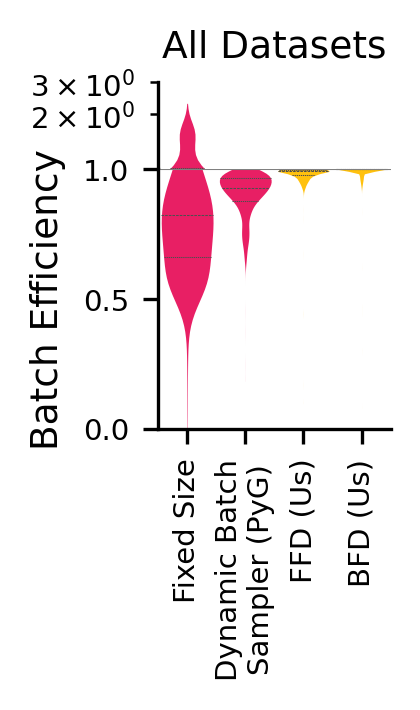

In [9]:
strategies = ["fixed", "sequential", "ffd", "bfd"]
labels = ["Fixed Size", "Dynamic Batch\nSampler (PyG)", "FFD (Us)", "BFD (Us)"]
fig, (ax_log, ax_linear) = plt.subplots(2, 1, figsize=(1, 1.5), gridspec_kw=dict(height_ratios=[0.25, 0.75], hspace=0.0))
styles = dict(
    data=packing.filter(pl.col("efficiency").gt(0)), x="strategy", y="efficiency", hue="strategy", order=strategies,
    palette=packing_palette, cut=0, gap=0.01, width=0.9, linewidth=0, bw_adjust=1.25, saturation=1, inner="quart",
    inner_kws=dict(linewidth=0.25), common_norm=False, density_norm="width", legend=False,
)
eps = 1e-5
sns.violinplot(**styles, ax=ax_linear)
ax_linear.set_ylim(-eps, 1 + eps)
ax_linear.axhline(1, lw=0.5, c="0.5")
sns.violinplot(**styles, log_scale=(False, True), ax=ax_log)
ax_log.set_ylim(1 + eps, 3)
ax_log.xaxis.set_visible(False)
ax_log.spines["bottom"].set_visible(False)
ax_log.set_ylabel("")
ax_log.set_title("All Datasets")
ax_linear.set_xticks(range(len(strategies)), labels, rotation=90)
ax_linear.set_xlabel("")
ax_linear.set_ylabel("Batch Efficiency")
sg.pl.save_panel(fig, OUT_DIR / "panel_e")

## Software versions

In [10]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    display(sc.logging.print_header())

Package,Version
matplotlib,3.10.8
numpy,1.26.4
polars,1.40.0
scanpy,1.11.5
seaborn,0.13.2
torch,2.5.1+cu121
segger,0.1.0
tqdm,4.67.3
Component,Info
Python,"3.11.15 | packaged by conda-forge | (main, Mar 5 2026, 16:45:40) [GCC 14.3.0]"
